# 10 — Model-Family Comparison

[Previous](./09_Class_Imbalance.ipynb) | [Repository guide](../README.md) | [Next](./11_Hyperparameter_Optimization.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** discover which kinds of models match this penalty-kick problem before tuning their settings.

We keep the same engineered features, preprocessing, five validation folds, original class balance, and F1 metric. Only the model changes.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


## 1. What is a model family?

A **model family** is a group of algorithms that learn patterns in a similar way.

- **Linear:** one weighted rule; fast and easy to inspect.
- **Distance-based:** nearby training rows vote.
- **Probabilistic:** estimates how likely each class is from feature distributions.
- **Support vector machine:** finds a boundary with a wide safety margin.
- **Tree:** learns readable `if/then` splits.
- **Bagging:** averages many trees trained independently to reduce instability.
- **Boosting:** builds trees in sequence; each new tree corrects earlier mistakes.
- **Neural network:** combines layers of learned weighted nonlinear transformations.

**Nonlinear** means the effect is not restricted to one straight boundary. A **hyperparameter** is a setting chosen before training, such as tree depth. Notebook 11 tunes those settings; this notebook uses sensible starter values.

In [1]:
from time import perf_counter

# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# A fixed seed makes randomized splits and experiments repeatable.
RANDOM_STATE = 42

# Optional display settings: readable tables and chart grids.
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)

print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")

Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)


## 2. Freeze everything except the model

The 34 engineered candidates from Notebook 05 are reused. IDs stay excluded. Missing values are filled, numbers are standardized, categories are one-hot encoded, and no balancing or outlier treatment is added.

This is a **controlled experiment**: if F1 changes, the model family caused the change rather than a new feature or split.

In [4]:
FEATURE_GROUPS = {
    "Relative ability": ["skill_advantage", "foot_difference", "skill_ratio_share", "skill_proxy"],
    "Match state": [
        "is_close_game", "is_losing", "is_tied", "is_winning", "match_status",
        "home_crowd_aligned", "is_poor_pitch", "final_extra_time",
    ],
    "Pressure components": ["pressure_index", "low_pressure", "late_minute", "extreme_pressure", "is_weak_player"],
    "Problem interactions": [
        "skill_gap_x_low_pressure", "disaster_combo", "pressure_x_weak",
        "pressure_skill", "keeper_pressure", "late_close_game",
    ],
    "Nonlinear and cyclical": [
        "player_form_squared", "keeper_form_squared", "skill_to_keeper_ratio",
        "score_x_minute", "minute_sin", "minute_cos", "humidity_sq_weak",
        "skill_keeper_product", "humidity_minute_interaction",
    ],
    "Composure proxies": ["clutch_boost", "choke_penalty"],
}


def add_engineered_features(frame):
    result = frame.copy()
    player_pct = result["player_last5_scored_percent"] / 100
    keeper_pct = result["goalkeeper_last5_saved_percent"] / 100
    minute_norm = result["minute_taken"] / 120
    humidity_norm = result["weather_humidity"] / 100
    score_diff = result["current_score_diff"]
    # A comparison gives True/False; astype(float) turns it into 1.0/0.0.
    close_game = (score_diff.abs() <= 1).astype(float)

    result["skill_advantage"] = result["player_last5_scored_percent"] - result["goalkeeper_last5_saved_percent"]
    result["foot_difference"] = result["strong_foot_usage"] - result["weak_foot_usage"]
    result["skill_ratio_share"] = player_pct / (player_pct + keeper_pct + 0.10)
    result["skill_proxy"] = (
        0.3 * result["strong_foot_usage"]
        + 0.2 * result["foot_difference"]
        + 0.5 * player_pct
    ).clip(0, 1)

    result["is_close_game"] = close_game
    result["is_losing"] = (score_diff < 0).astype(float)
    result["is_tied"] = (score_diff == 0).astype(float)
    result["is_winning"] = (score_diff > 0).astype(float)
    result["match_status"] = np.select(
        [(score_diff > 0), (score_diff == 0), (score_diff < 0)], [0.0, 1.0, 2.0], default=np.nan
    )
    result["home_crowd_aligned"] = (
        (result["home_or_away"] == "Home") & (result["crowd_behind_goal"] == "Home")
    ).astype(float)
    result["is_poor_pitch"] = (result["pitch_condition"] == "Poor").astype(float)
    result["final_extra_time"] = (
        (result["match_type"] == "Final") & (result["minute_taken"] > 90)
    ).astype(float)

    pressure_map = {"League": 0.2, "Cup": 0.4, "Playoff": 0.5, "Final": 0.6, "Friendly": 0.1}
    match_pressure = result["match_type"].map(pressure_map).fillna(0.3)
    score_pressure = 1.0 / (score_diff.abs() + 1)
    result["pressure_index"] = (0.5 * match_pressure + 0.25 * minute_norm + 0.25 * score_pressure).clip(0, 1)
    result["low_pressure"] = 1 - result["pressure_index"]
    result["late_minute"] = (minute_norm - 0.625).clip(0, 1)
    result["extreme_pressure"] = (result["pressure_index"] > 0.75).astype(float)
    result["is_weak_player"] = (player_pct < 0.4).astype(float)

    result["skill_gap_x_low_pressure"] = (player_pct - keeper_pct) * result["low_pressure"]
    result["disaster_combo"] = result["late_minute"] * result["is_losing"] * result["is_poor_pitch"]
    result["pressure_x_weak"] = result["pressure_index"] * result["is_weak_player"]
    result["pressure_skill"] = close_game * result["player_last5_scored_percent"]
    result["keeper_pressure"] = (score_diff <= 0).astype(float) * result["goalkeeper_last5_saved_percent"]
    result["late_close_game"] = close_game * minute_norm

    result["player_form_squared"] = result["player_last5_scored_percent"] ** 2
    result["keeper_form_squared"] = result["goalkeeper_last5_saved_percent"] ** 2
    result["skill_to_keeper_ratio"] = result["player_last5_scored_percent"] / (
        result["goalkeeper_last5_saved_percent"] + 1
    )
    result["score_x_minute"] = score_diff * result["minute_taken"]
    result["minute_sin"] = np.sin(2 * np.pi * (result["minute_taken"] / 90))
    result["minute_cos"] = np.cos(4 * np.pi * (result["minute_taken"] / 90))
    result["humidity_sq_weak"] = (humidity_norm ** 2) * result["weak_foot_usage"]
    result["skill_keeper_product"] = player_pct * keeper_pct
    result["humidity_minute_interaction"] = humidity_norm * result["minute_sin"]

    result["clutch_boost"] = (result["skill_proxy"] > 0.7).astype(float) * result["extreme_pressure"]
    result["choke_penalty"] = (result["skill_proxy"] < 0.3).astype(float) * result["extreme_pressure"]
    return result


X = add_engineered_features(train.drop(columns=[TARGET] + ID_COLUMNS))
y = train[TARGET].astype(int)
categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()
numerical_columns = X.select_dtypes(include=np.number).columns.tolist()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X, y))

print(f"Model inputs: {X.shape[1]} columns before one-hot encoding")
print(f"Numerical: {len(numerical_columns)} | Categorical: {len(categorical_columns)} | Folds: {len(folds)}")

Model inputs: 49 columns before one-hot encoding
Numerical: 44 | Categorical: 5 | Folds: 5


In [5]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numerical_columns),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_columns),
    ], sparse_threshold=0)

## 3. Starter models to compare

Each row below is one representative algorithm, not every possible algorithm in its family.

In [6]:
model_specs = [
    {
        "family": "Linear",
        "model": "Logistic regression",
        "estimator": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
        "score_method": "predict_proba",
        "threshold": 0.50,
    },
    {
        "family": "Distance",
        "model": "K-nearest neighbours",
        "estimator": KNeighborsClassifier(n_neighbors=25, weights="distance", n_jobs=-1),
        "score_method": "predict_proba",
        "threshold": 0.50,
    },
    {
        "family": "Probabilistic",
        "model": "Gaussian Naive Bayes",
        "estimator": GaussianNB(),
        "score_method": "predict_proba",
        "threshold": 0.50,
    },
    {
        "family": "Support vector",
        "model": "Linear SVM",
        "estimator": LinearSVC(C=1.0, dual="auto", random_state=RANDOM_STATE),
        "score_method": "decision_function",
        "threshold": 0.0,
    },
    {
        "family": "Single tree",
        "model": "Decision tree",
        "estimator": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE),
        "score_method": "predict_proba",
        "threshold": 0.50,
    },
    {
        "family": "Bagging",
        "model": "Random forest",
        "estimator": RandomForestClassifier(
            n_estimators=250, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1
        ),
        "score_method": "predict_proba",
        "threshold": 0.50,
    },
    {
        "family": "Bagging",
        "model": "Extra Trees",
        "estimator": ExtraTreesClassifier(
            n_estimators=250, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1
        ),
        "score_method": "predict_proba",
        "threshold": 0.50,
    },
    {
        "family": "Boosting",
        "model": "Histogram gradient boosting",
        "estimator": HistGradientBoostingClassifier(
            max_iter=250, learning_rate=0.05, max_leaf_nodes=31, random_state=RANDOM_STATE
        ),
        "score_method": "predict_proba",
        "threshold": 0.50,
    },
    {
        "family": "Boosting",
        "model": "XGBoost",
        "estimator": XGBClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=5,
            subsample=0.85, colsample_bytree=0.85,
            eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1,
        ),
        "score_method": "predict_proba",
        "threshold": 0.50,
    },
    {
        "family": "Boosting",
        "model": "LightGBM",
        "estimator": LGBMClassifier(
            n_estimators=300, learning_rate=0.05, num_leaves=31,
            subsample=0.85, colsample_bytree=0.85,
            random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1,
        ),
        "score_method": "predict_proba",
        "threshold": 0.50,
    },
    {
        "family": "Boosting",
        "model": "CatBoost",
        "estimator": CatBoostClassifier(
            iterations=300, learning_rate=0.05, depth=6,
            random_seed=RANDOM_STATE, verbose=False, allow_writing_files=False,
        ),
        "score_method": "predict_proba",
        "threshold": 0.50,
    },
    {
        "family": "Neural network",
        "model": "Multilayer perceptron",
        "estimator": MLPClassifier(
            hidden_layer_sizes=(64, 32), max_iter=250, early_stopping=True,
            random_state=RANDOM_STATE,
        ),
        "score_method": "predict_proba",
        "threshold": 0.50,
    },
]

model_summary = pd.DataFrame([
    ["Logistic regression", "Weighted straight boundary", "Fast, interpretable reference"],
    ["K-nearest neighbours", "Nearby rows vote", "Sensitive to scaling and local noise"],
    ["Gaussian Naive Bayes", "Class-specific feature distributions", "Strong independence assumption"],
    ["Linear SVM", "Wide-margin linear boundary", "No probability without calibration"],
    ["Decision tree", "One sequence of if/then splits", "Readable but unstable"],
    ["Random forest", "Average bootstrapped trees", "Stable; larger and slower"],
    ["Extra Trees", "Average more-random trees", "Fast variance reduction"],
    ["Histogram gradient boosting", "Sequential histogram-based trees", "Strong tabular default"],
    ["XGBoost", "Regularized sequential trees", "Many useful controls"],
    ["LightGBM", "Leaf-wise sequential trees", "Fast; can overfit small leaves"],
    ["CatBoost", "Ordered boosting trees", "Strong on tabular data"],
    ["Multilayer perceptron", "Layers of nonlinear weights", "Needs scaling and careful tuning"],
], columns=["model", "how it learns", "main point"])
display(model_summary.style.hide(axis="index"))

model,how it learns,main point
Logistic regression,Weighted straight boundary,"Fast, interpretable reference"
K-nearest neighbours,Nearby rows vote,Sensitive to scaling and local noise
Gaussian Naive Bayes,Class-specific feature distributions,Strong independence assumption
Linear SVM,Wide-margin linear boundary,No probability without calibration
Decision tree,One sequence of if/then splits,Readable but unstable
Random forest,Average bootstrapped trees,Stable; larger and slower
Extra Trees,Average more-random trees,Fast variance reduction
Histogram gradient boosting,Sequential histogram-based trees,Strong tabular default
XGBoost,Regularized sequential trees,Many useful controls
LightGBM,Leaf-wise sequential trees,Fast; can overfit small leaves


## 4. Leakage-safe OOF comparison

For every model, preprocessing is refitted inside the same five folds. **OOF** means each row is predicted by a model that did not train on that row.

`fit seconds` measures this Kaggle run only; it is a practical comparison, not a universal speed ranking.

In [7]:
rows = []
oof_classes = {}

for spec in model_specs:
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", spec["estimator"]),
    ])

    start = perf_counter()
    raw_scores = cross_val_predict(
        pipeline,
        X,
        y,
        cv=folds,
        method=spec["score_method"],
        n_jobs=1,
    )
    elapsed = perf_counter() - start

    scores = raw_scores[:, 1] if spec["score_method"] == "predict_proba" else raw_scores
    predictions = (scores >= spec["threshold"]).astype(int)
    fold_f1 = [f1_score(y.iloc[valid_index], predictions[valid_index]) for _, valid_index in folds]

    rows.append({
        "family": spec["family"],
        "model": spec["model"],
        "f1": f1_score(y, predictions),
        "f1_std": np.std(fold_f1, ddof=1),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "accuracy": accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, scores),
        "fit_seconds": elapsed,
    })
    oof_classes[spec["model"]] = predictions
    print(f"Finished {spec['model']}: F1 {rows[-1]['f1']:.4f} in {elapsed:.1f}s")

results = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
display(results)

Finished Logistic regression: F1 0.8847 in 4.9s
Finished K-nearest neighbours: F1 0.8621 in 2.2s
Finished Gaussian Naive Bayes: F1 0.7871 in 0.9s
Finished Linear SVM: F1 0.8842 in 2.9s
Finished Decision tree: F1 0.9112 in 2.2s
Finished Random forest: F1 0.9312 in 18.9s
Finished Extra Trees: F1 0.9340 in 11.1s
Finished Histogram gradient boosting: F1 0.9445 in 13.7s
Finished XGBoost: F1 0.9442 in 6.4s


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Finished LightGBM: F1 0.9448 in 6.9s
Finished CatBoost: F1 0.9462 in 12.5s
Finished Multilayer perceptron: F1 0.9456 in 12.5s


,family,model,f1,f1_std,precision,recall,balanced_accuracy,accuracy,roc_auc,fit_seconds
0,Boosting,CatBoost,0.9462,0.0045,0.9488,0.9437,0.9510,0.9517,0.9927,12.5404
1,Neural network,Multilayer perceptron,0.9456,0.0030,0.9472,0.9440,0.9505,0.9511,0.9918,12.4664
2,Boosting,LightGBM,0.9448,0.0064,0.9454,0.9442,0.9498,0.9504,0.9918,6.8772
3,Boosting,Histogram gradient boosting,0.9445,0.0054,0.9453,0.9436,0.9495,0.9500,0.9915,13.6741
4,Boosting,XGBoost,0.9442,0.0049,0.9463,0.9421,0.9492,0.9499,0.9918,6.3933
5,Bagging,Extra Trees,0.9340,0.0066,0.9359,0.9321,0.9399,0.9407,0.9866,11.1001
6,Bagging,Random forest,0.9312,0.0096,0.9314,0.9309,0.9374,0.9381,0.9856,18.9167
7,Single tree,Decision tree,0.9112,0.0066,0.9148,0.9076,0.9192,0.9204,0.9732,2.1777
8,Linear,Logistic regression,0.8847,0.0061,0.8916,0.8779,0.8953,0.8970,0.9625,4.9094
9,Support vector,Linear SVM,0.8842,0.0068,0.8933,0.8753,0.8949,0.8969,0.9625,2.9097


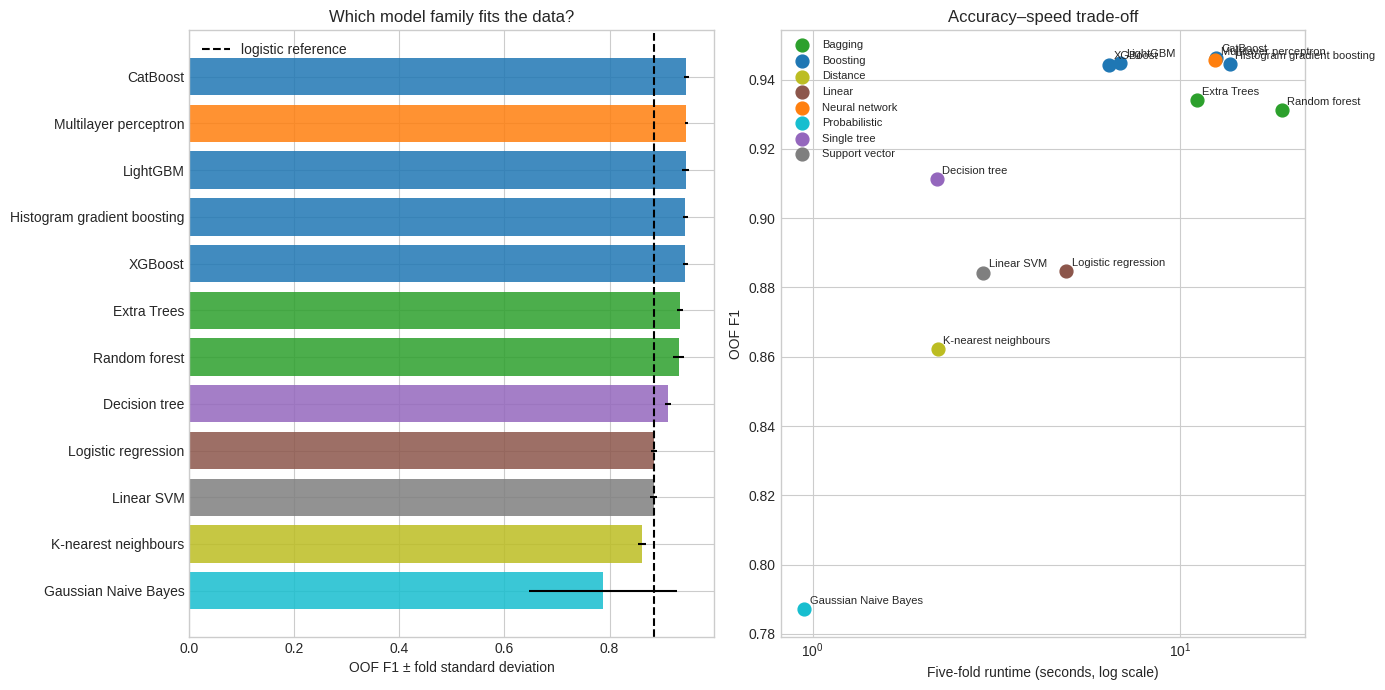

In [8]:
reference = results.loc[results["model"].eq("Logistic regression")].iloc[0]
ordered = results.sort_values("f1")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
family_colors = {
    family: color for family, color in zip(
        results["family"].unique(),
        plt.cm.tab10(np.linspace(0, 1, results["family"].nunique())),
    )
}
bar_colors = [family_colors[family] for family in ordered["family"]]

axes[0].barh(ordered["model"], ordered["f1"], xerr=ordered["f1_std"], color=bar_colors, alpha=.85)
axes[0].axvline(reference["f1"], color="black", linestyle="--", label="logistic reference")
axes[0].set(title="Which model family fits the data?", xlabel="OOF F1 ± fold standard deviation", ylabel="")
axes[0].legend()

for family, group in results.groupby("family"):
    axes[1].scatter(group["fit_seconds"], group["f1"], s=85, label=family, color=family_colors[family])
for _, row in results.iterrows():
    axes[1].annotate(row["model"], (row["fit_seconds"], row["f1"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
axes[1].set(title="Accuracy–speed trade-off", xlabel="Five-fold runtime (seconds, log scale)", ylabel="OOF F1", xscale="log")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### Concrete dataset example: models can disagree

The next table shows the same eight penalties and several OOF predictions. Disagreement means the model families learned different boundaries from the same data.

This is useful for later error analysis and ensembling; it does not mean that majority voting is automatically better.

In [9]:
best_model_name = results.iloc[0]["model"]
example_models = list(dict.fromkeys([
    "Logistic regression",
    "K-nearest neighbours",
    "Decision tree",
    "Random forest",
    best_model_name,
]))

disagreement_count = np.sum(
    np.column_stack([oof_classes[name] for name in example_models]) !=
    np.column_stack([oof_classes[name] for name in example_models])[:, [0]],
    axis=1,
)
example_index = np.argsort(disagreement_count)[-8:][::-1]

example = pd.DataFrame({
    "actual": y.iloc[example_index].to_numpy(),
    **{name: oof_classes[name][example_index] for name in example_models},
}, index=train.iloc[example_index]["id"].rename("penalty id"))
display(example)
print("Rows were chosen because the displayed models disagreed most; every prediction is out-of-fold.")

,actual,Logistic regression,K-nearest neighbours,Decision tree,Random forest,CatBoost
penalty id,,,,,,
6776,1,0,1,1,1,1
6785,0,1,0,0,0,0
6793,1,1,0,0,0,0
6819,1,0,1,1,1,1
18385,1,0,1,1,1,1
6872,1,0,1,1,1,1
6877,1,0,1,1,1,1
6878,1,1,0,0,0,0


Rows were chosen because the displayed models disagreed most; every prediction is out-of-fold.


## 5. Decision

The best untuned model becomes a tuning candidate, not the automatic final solution. We also keep a simpler reference and any near-tied model from a different family.

A small point-estimate lead can disappear with different folds. `F1 standard deviation` shows the ordinary fold-to-fold variation we compare against.

In [10]:
best = results.iloc[0]
gain = best["f1"] - reference["f1"]
near_best = results.loc[results["f1"] >= best["f1"] - best["f1_std"], ["family", "model", "f1", "fit_seconds"]]

print(f"Logistic reference: F1 {reference['f1']:.4f}")
print(f"Best starter model: {best['model']} ({best['family']}) | F1 {best['f1']:.4f} | change {gain:+.4f}")
print("Models within one best-model fold standard deviation:")
display(near_best.style.hide(axis="index").format({"f1": "{:.4f}", "fit_seconds": "{:.1f}"}))
print("Decision: tune the strongest two or three diverse families in Notebook 11; keep logistic regression as the sanity-check reference.")

Logistic reference: F1 0.8847
Best starter model: CatBoost (Boosting) | F1 0.9462 | change +0.0616
Models within one best-model fold standard deviation:


family,model,f1,fit_seconds
Boosting,CatBoost,0.9462,12.5
Neural network,Multilayer perceptron,0.9456,12.5
Boosting,LightGBM,0.9448,6.9
Boosting,Histogram gradient boosting,0.9445,13.7
Boosting,XGBoost,0.9442,6.4


Decision: tune the strongest two or three diverse families in Notebook 11; keep logistic regression as the sanity-check reference.


## Other useful alternatives

- **Ridge, Lasso, Elastic Net:** linear models with different coefficient penalties.
- **Quadratic Discriminant Analysis:** class-specific curved probability boundary; sensitive to correlated inputs.
- **Radius Neighbours / Nearest Centroid:** other distance rules.
- **Bernoulli Naive Bayes:** suited to binary features.
- **RBF SVM:** nonlinear margin model; often expensive on 20,000 rows.
- **AdaBoost / classic Gradient Boosting:** important boosting variants; the executed boosters already represent this family.
- **Balanced Random Forest:** combines model choice with class balancing, so it belongs in a controlled follow-up.
- **Explainable Boosting Machine:** interpretable boosted shape functions; requires an additional package.
- **TabNet / FT-Transformer:** neural models designed for tables; heavier and usually need careful tuning.

Running every named algorithm would create repetition. The twelve executed models cover the main learning mechanisms and make the next tuning decision evidence-based.

In [11]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

results_dir = Path("/kaggle/working")
results_dir.mkdir(parents=True, exist_ok=True)
output_path = results_dir / "10_model_family_comparison.csv"
results.to_csv(output_path, index=False)
print(f"Saved: {output_path}")

Saved: /kaggle/working/10_model_family_comparison.csv


## Why this decision is justified

**Technical evidence:** all twelve models use identical inputs and validation rows. F1, precision, recall, accuracy, ROC-AUC, fold variability, and runtime are compared together.

**Theoretical reason:** different families make different assumptions. We choose tuning candidates from the families that fit these interactions well, while retaining a simple linear reference to detect whether later complexity earns its cost.